In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#0. Training over epochs



In [2]:
df = pd.read_csv('/content/drive/MyDrive/SI/callbacks/training_log.csv')
df.describe()

NameError: name 'pd' is not defined

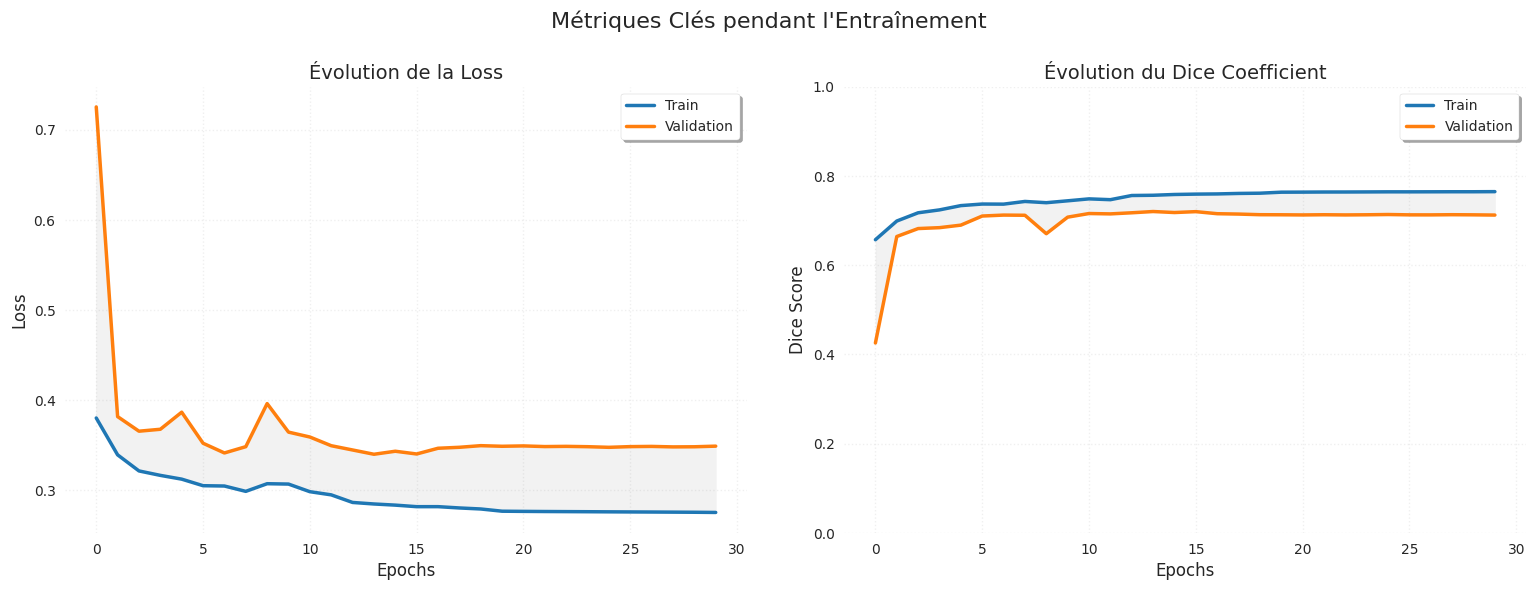

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configuration du style
plt.style.use('seaborn-v0_8')
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'grid.alpha': 0.3
})

def plot_essential_metrics(df):
    """Visualise uniquement la loss et le Dice coefficient"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Courbe de Loss
    sns.lineplot(data=df, x='epoch', y='loss', label='Train',
                ax=ax1, color='#1f77b4', linewidth=2.5)
    sns.lineplot(data=df, x='epoch', y='val_loss', label='Validation',
                ax=ax1, color='#ff7f0e', linewidth=2.5)
    ax1.fill_between(df['epoch'], df['loss'], df['val_loss'],
                   color='gray', alpha=0.1)
    ax1.set_title('Évolution de la Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend(frameon=True, shadow=True)
    ax1.grid(True, linestyle=':')

    # 2. Courbe de Dice Coefficient
    sns.lineplot(data=df, x='epoch', y='dice_coef', label='Train',
                ax=ax2, color='#1f77b4', linewidth=2.5)
    sns.lineplot(data=df, x='epoch', y='val_dice_coef', label='Validation',
                ax=ax2, color='#ff7f0e', linewidth=2.5)
    ax2.fill_between(df['epoch'], df['dice_coef'], df['val_dice_coef'],
                   color='gray', alpha=0.1)
    ax2.set_title('Évolution du Dice Coefficient')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Dice Score')
    ax2.set_ylim(0, 1)  # Le Dice est entre 0 et 1
    ax2.legend(frameon=True, shadow=True)
    ax2.grid(True, linestyle=':')

    # Optimisation de l'espace
    plt.tight_layout(pad=3)

    # Ajout d'un titre général
    fig.suptitle('Métriques Clés pendant l\'Entraînement', y=1.02, fontsize=16)

    # Sauvegarde
    plt.savefig('essential_metrics.pdf')
    plt.show()

# Exemple d'utilisation
if __name__ == "__main__":
    # Chargement des données (à adapter)
    df = pd.read_csv('/content/drive/MyDrive/SI/callbacks/training_log.csv')

    # Appel de la fonction
    plot_essential_metrics(df)

#1. Load data

In [7]:
import os
import numpy as np
import random
input_dir = "/content/drive/MyDrive/SI/data_2023"
target_dir = "/content/drive/MyDrive/SI/mask_via_2023"
img_size = (160, 160)
num_classes = 2
batch_size = 8

input_img_paths = sorted(
    [
        os.path.join(input_dir, fname)
        for fname in os.listdir(input_dir)
        if fname.endswith(".png")
    ]
)
target_img_paths = sorted(
    [
        os.path.join(target_dir, fname)
        for fname in os.listdir(target_dir)
        if fname.endswith(".png") and not fname.startswith(".")
    ]
)

print("Number of samples:", len(input_img_paths))
for input_path, target_path in zip(input_img_paths[:10], target_img_paths[:10]):
    print(input_path, "|", target_path)

Number of samples: 2552
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T03-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T03-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T06-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T06-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T09-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T09-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T12-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T12-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T15-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T15-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T18-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T18-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T21-00-00.000Z.png 

In [8]:
# Set split ratios
val_ratio = 0.1
test_ratio = 0.1  # 10% for test, adjust as needed

# Shuffle with fixed seed for reproducibility
random.seed(1337)
combined = list(zip(input_img_paths, target_img_paths))
random.shuffle(combined)
input_img_paths, target_img_paths = zip(*combined)

# Calculate sizes
total_samples = len(input_img_paths)
val_samples = int(total_samples * val_ratio)
test_samples = int(total_samples * test_ratio)

# Split into train / val / test
train_input_img_paths = input_img_paths[:-(val_samples + test_samples)]
train_target_img_paths = target_img_paths[:-(val_samples + test_samples)]

val_input_img_paths = input_img_paths[-(val_samples + test_samples):-test_samples]
val_target_img_paths = target_img_paths[-(val_samples + test_samples):-test_samples]

test_input_img_paths = input_img_paths[-test_samples:]
test_target_img_paths = target_img_paths[-test_samples:]


print(f"Train samples: {len(train_input_img_paths)}")
print(f"Val samples:   {len(val_input_img_paths)}")
print(f"Test samples:  {len(test_input_img_paths)}")


Train samples: 2042
Val samples:   255
Test samples:  255


#2. Load model

In [9]:
from tensorflow.keras.utils import register_keras_serializable

@register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1):
    intersection = K.sum(y_true * y_pred, axis=[1,2,3])
    union = K.sum(y_true, axis=[1,2,3]) + K.sum(y_pred, axis=[1,2,3])
    return K.mean((2. * intersection + smooth) / (union + smooth), axis=0)

@register_keras_serializable()
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

@register_keras_serializable()
def combined_loss(y_true, y_pred):
    return binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

In [10]:
from tensorflow import keras

# Load model from .keras file
modele = keras.models.load_model("/content/drive/MyDrive/SI/callbacks/model_best.keras")


#3. random and Visual test of the model

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
(512, 512)


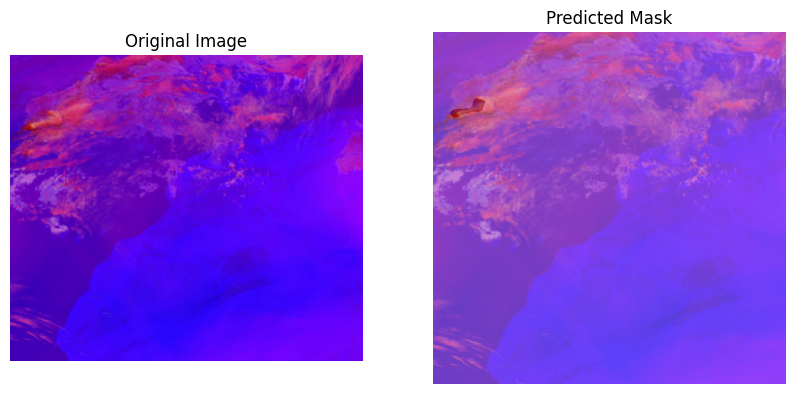

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt
import random

# ===== 1. Predict function =====
def predict_segmentation_keras(image_path, model, img_size=(512, 512)):
    # Load and preprocess image
    image = Image.open(image_path).convert("RGB")
    image_resized = image.resize(img_size)
    image_array = np.array(image_resized) / 255.0  # normalize to [0,1]
    image_tensor = np.expand_dims(image_array, axis=0)  # [1, H, W, 3]

    # Run prediction
    pred = model.predict(image_tensor)  # shape [1, H, W, 1] for binary
    mask = pred.squeeze()  # [H, W]

    # Threshold
    binary_mask = (mask > 0.5).astype(np.uint8)

    return image, binary_mask

# ===== 2. Visualization =====
def plot_segmentation(image, mask):
    plt.figure(figsize=(10, 5))

    # Original image
    plt.subplot(1, 2, 1)
    plt.title("Original Image")
    plt.imshow(image)
    plt.axis("off")

    # Mask overlay
    plt.subplot(1, 2, 2)
    plt.title("Predicted Mask")
    plt.imshow(image)
    plt.imshow(mask, alpha=0.25, cmap='Reds')
    plt.axis("off")

    plt.show()

# ===== 3. Run prediction =====
image_path = random.choice(test_input_img_paths)  # from your earlier split
image, mask = predict_segmentation_keras(image_path, modele, img_size=(512, 512))
print(mask.shape)
plot_segmentation(image, mask)


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Original Image Size (W, H): (600, 521)
Mask Array Shape (H, W):    (521, 600)


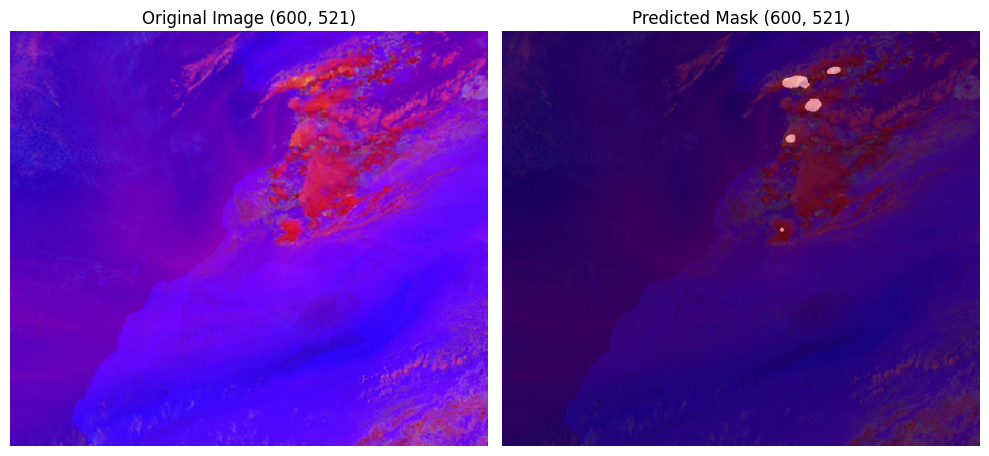

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

# ===== 1. Predict function =====
def predict_segmentation_keras(image_path, model, img_size=(512, 512)):
    # Load original image
    image = Image.open(image_path).convert("RGB")
    orig_w, orig_h = image.size  # PIL image sizes are (width, height)

    # Preprocess image for model input
    image_resized = image.resize(img_size)
    image_array = np.array(image_resized) / 255.0  # normalize to [0, 1]
    image_tensor = np.expand_dims(image_array, axis=0)  # [1, H, W, 3]

    # Run prediction
    pred = model.predict(image_tensor)  # shape [1, H, W, 1]
    mask = pred.squeeze()  # [H, W]

    # Resize binary mask back to original image dimensions
    mask_pil = Image.fromarray((mask > 0.5).astype(np.uint8))
    mask_resized = mask_pil.resize((orig_w, orig_h), resample=Image.NEAREST)
    binary_mask = np.array(mask_resized)

    return image, binary_mask

# ===== 2. Visualization =====
def plot_segmentation(image, mask):
    plt.figure(figsize=(10, 5))

    # Original image
    plt.subplot(1, 4, 1)
    plt.title(f"Original Image {image.size}")
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(1, 4, 3)
    mask_path =
    plt.title(f"Predicted Mask ground trunt ")
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5, cmap='gray')
    plt.axis("off")

    # Mask overlay
    plt.subplot(1, 4, 2)
    plt.title(f"Predicted Mask unet  {mask.shape[::-1]}")
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5, cmap='gray')
    plt.axis("off")

    plt.subplot(1, 4, 4)
    mask_path =
    plt.title(f"Predicted Mask Open CV {mask.shape[::-1]}")
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5, cmap='gray')
    plt.axis("off")


    plt.tight_layout()
    plt.show()

# ===== 3. Run prediction on a specific image =====
specific_image_path = input_img_paths[10]  # Replace with your actual file path

image, mask = predict_segmentation_keras(specific_image_path, modele, img_size=(512, 512))

print(f"Original Image Size (W, H): {image.size}")
print(f"Mask Array Shape (H, W):    {mask.shape}")

plot_segmentation(image, mask)

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step
Original Image Size (W, H): (600, 521)
UNet Mask Shape (H, W):     (521, 600)


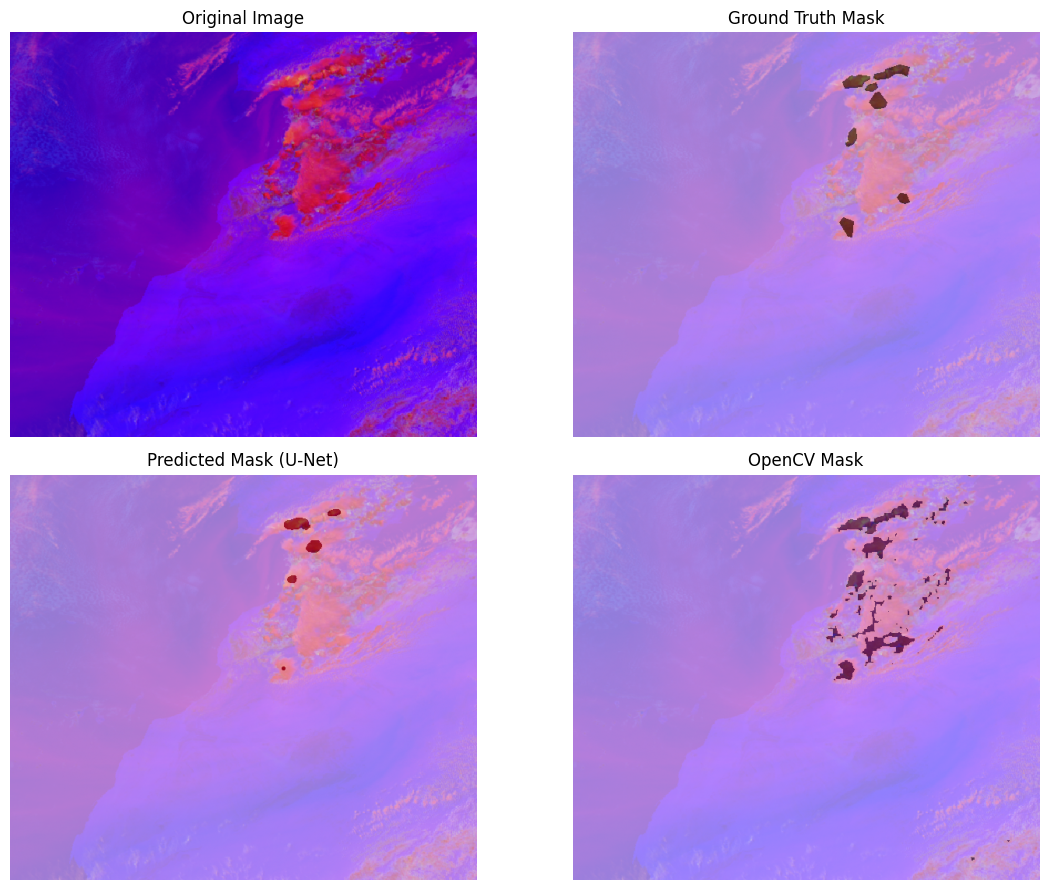

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

# ===== Helper to load & resize external binary masks =====
def load_mask(mask_path, target_size):
    """Loads a mask image, converts it to binary (0/1), and resizes to target_size (W, H)."""
    if mask_path is None:
        return None
    mask_img = Image.open(mask_path).convert("L")  # Load as grayscale
    mask_resized = mask_img.resize(target_size, resample=Image.NEAREST)
    mask_array = (np.array(mask_resized) > 0).astype(np.uint8)  # Ensure binary {0, 1}
    return mask_array

# ===== 1. Predict function =====
def predict_segmentation_keras(image_path, model, img_size=(512, 512)):
    # Load original image
    image = Image.open(image_path).convert("RGB")
    orig_w, orig_h = image.size  # PIL image sizes are (width, height)

    # Preprocess image for model input
    image_resized = image.resize(img_size)
    image_array = np.array(image_resized) / 255.0  # normalize to [0, 1]
    image_tensor = np.expand_dims(image_array, axis=0)  # [1, H, W, 3]

    # Run prediction
    pred = model.predict(image_tensor)  # shape [1, H, W, 1]
    mask = pred.squeeze()  # [H, W]

    # Resize predicted binary mask back to original image dimensions
    mask_pil = Image.fromarray((mask > 0.5).astype(np.uint8))
    mask_resized = mask_pil.resize((orig_w, orig_h), resample=Image.NEAREST)
    binary_mask = np.array(mask_resized)

    return image, binary_mask

# ===== 2. Visualization =====
def plot_segmentation(image, unet_mask, gt_mask_path=None, opencv_mask_path=None):
    orig_size = image.size  # (width, height)

    # Load external masks matching original image resolution
    gt_mask = load_mask(gt_mask_path, orig_size)
    opencv_mask = load_mask(opencv_mask_path, orig_size)

    plt.figure(figsize=(12, 9))

    # 1. Original Image
    plt.subplot(2, 2, 1)
    plt.title(f"Original Image")
    plt.imshow(image)
    plt.axis("off")

    # 2. Predicted Mask (UNet)
    plt.subplot(2, 2, 3)
    plt.title(f"Predicted Mask (U-Net)")
    plt.imshow(image)
    plt.imshow(unet_mask, alpha=0.5, cmap='Reds')
    plt.axis("off")

    # 3. Ground Truth Mask
    plt.subplot(2, 2, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(image)
    if gt_mask is not None:
        plt.imshow(gt_mask, alpha=0.5, cmap='Greens')
    else:
        plt.text(0.5, 0.5, "No Path Provided", ha='center', va='center', transform=plt.gca().transAxes)
    plt.axis("off")

    # 4. OpenCV Mask
    plt.subplot(2, 2, 4)
    plt.title("OpenCV Mask")
    plt.imshow(image)
    if opencv_mask is not None:
        plt.imshow(opencv_mask, alpha=0.5, cmap='Blues')
    else:
        plt.text(0.5, 0.5, "No Path Provided", ha='center', va='center', transform=plt.gca().transAxes)
    plt.axis("off")

    plt.tight_layout()
    plt.savefig('all comaparision.png')
    plt.show()

# ===== 3. Run prediction on a specific image =====
specific_image_path = input_img_paths[10]
gt_mask_path = target_img_paths[10]       # Path to your ground truth mask image

target_opencv = "/content/drive/MyDrive/SI/mask_opencv_2023"
opencv_mask_path =  '/content/drive/MyDrive/SI/mask_opencv_2023/mask_prod_2023-05-18T15-00-00.000Z.png'

image, unet_mask = predict_segmentation_keras(specific_image_path, modele, img_size=(512, 512))

print(f"Original Image Size (W, H): {image.size}")
print(f"UNet Mask Shape (H, W):     {unet_mask.shape}")

plot_segmentation(
    image=image,
    unet_mask=unet_mask,
    gt_mask_path=gt_mask_path,
    opencv_mask_path=opencv_mask_path
)

1


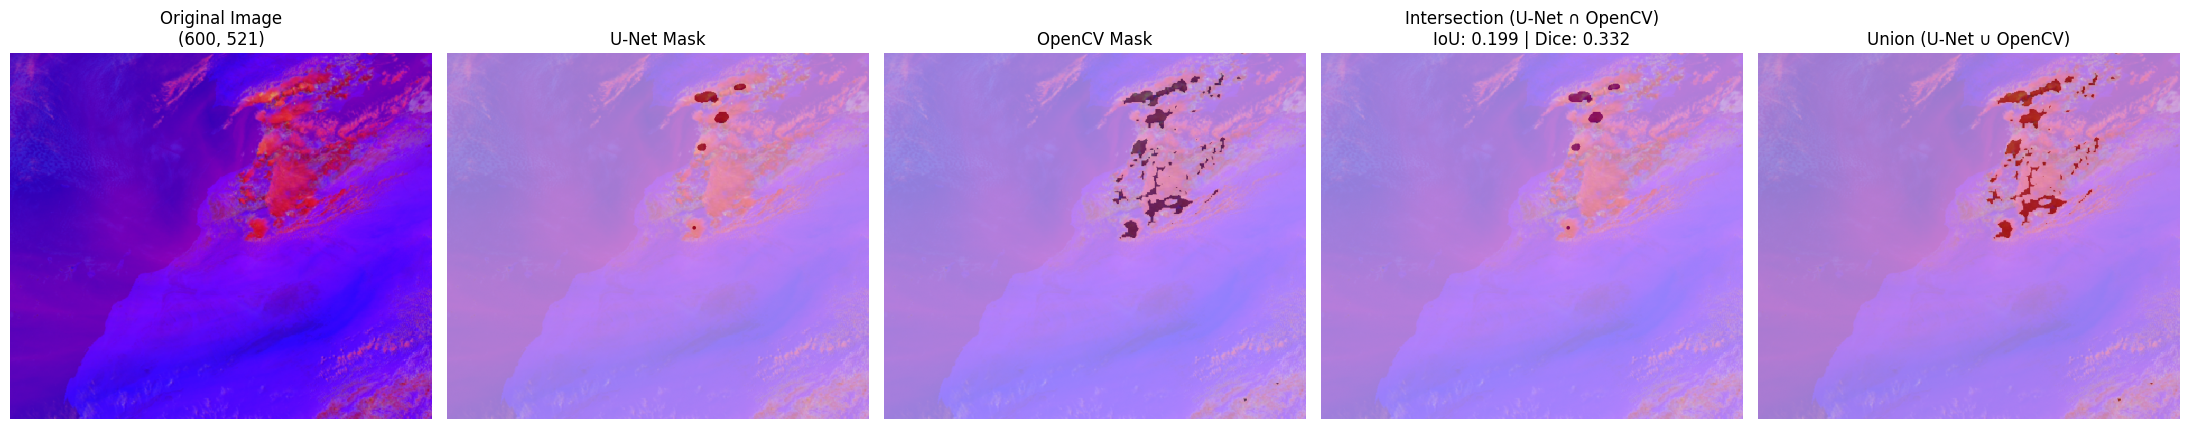

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_mask_comparison(image, unet_mask, gt_mask_path=None, opencv_mask_path=None):
    """
    Plots Original Image, U-Net Mask, OpenCV Mask, Intersection, and Union between U-Net & OpenCV.
    """
    orig_size = image.size  # (W, H)

    # Load external masks using the load_mask helper from before
    gt_mask = load_mask(gt_mask_path, orig_size)
    opencv_mask = load_mask(opencv_mask_path, orig_size)

    # Ensure OpenCV mask exists for logical operations
    if opencv_mask is None:
        print("Error: opencv_mask_path is required to compute Intersection and Union.")
        return

    # Logical operations (convert to boolean arrays)
    unet_bool = unet_mask > 0
    opencv_bool = opencv_mask > 0

    intersection = np.logical_and(unet_bool, opencv_bool).astype(np.uint8)
    union = np.logical_or(unet_bool, opencv_bool,gt_mask).astype(np.uint8)

    # Calculate IoU and Dice Score between U-Net and OpenCV
    intersection_area = np.sum(intersection)
    union_area = np.sum(union)

    iou = intersection_area / union_area if union_area > 0 else 0.0
    dice = (2.0 * intersection_area) / (np.sum(unet_bool) + np.sum(opencv_bool)) if (np.sum(unet_bool) + np.sum(opencv_bool)) > 0 else 0.0

    # Plot 5 subplots side-by-side
    plt.figure(figsize=(22, 5))

    # 1. Original Image
    plt.subplot(1, 5, 1)
    plt.title(f"Original Image\n{image.size}")
    plt.imshow(image)
    plt.axis("off")

    # 2. U-Net Mask
    plt.subplot(1, 5, 2)
    plt.title("U-Net Mask")
    plt.imshow(image)
    plt.imshow(unet_mask, alpha=0.5, cmap='Reds')
    plt.axis("off")

    # 3. OpenCV Mask
    plt.subplot(1, 5, 3)
    plt.title("OpenCV Mask")
    plt.imshow(image)
    plt.imshow(opencv_mask, alpha=0.5, cmap='Blues')
    plt.axis("off")
    print(unet_mask.max())

    # 4. Intersection (Agreement)
    plt.subplot(1, 5, 4)
    plt.title(f"Intersection (U-Net ∩ OpenCV)\nIoU: {iou:.3f} | Dice: {dice:.3f}")
    plt.imshow(image)
    plt.imshow(intersection, alpha=0.5, cmap='Purples')
    plt.axis("off")

    # 5. Union (Combined Regions)
    plt.subplot(1, 5, 5)
    plt.title("Union (U-Net ∪ OpenCV)")
    plt.imshow(image)
    plt.imshow(union, alpha=0.5, cmap='Oranges')
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# ===== Example Usage =====
plot_mask_comparison(
    image=image,
    unet_mask=unet_mask,
    gt_mask_path=gt_mask_path,
    opencv_mask_path=opencv_mask_path
)

In [5]:
!pip install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 23.4 MB/s eta 0:00:00



🚀 Running segmentation model over images...
📁 Found 1024 images to predict in /content/drive/MyDrive/SI/data_2024/
  Processed [10/1024] images...
  Processed [20/1024] images...
  Processed [30/1024] images...
  Processed [40/1024] images...
  Processed [50/1024] images...
  Processed [60/1024] images...
  Processed [70/1024] images...
  Processed [80/1024] images...
  Processed [90/1024] images...
  Processed [100/1024] images...
  Processed [110/1024] images...
  Processed [120/1024] images...
  Processed [130/1024] images...
  Processed [140/1024] images...
  Processed [150/1024] images...
  Processed [160/1024] images...
  Processed [170/1024] images...
  Processed [180/1024] images...
  Processed [190/1024] images...
  Processed [200/1024] images...
  Processed [210/1024] images...
  Processed [220/1024] images...
  Processed [230/1024] images...
  Processed [240/1024] images...
  Processed [250/1024] images...
  Processed [260/1024] images...
  Processed [270/1024] images...
  

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


✅ Map successfully generated & saved to: /content/drive/MyDrive/SI/fig/nombre_episodes_convection_maroc.png


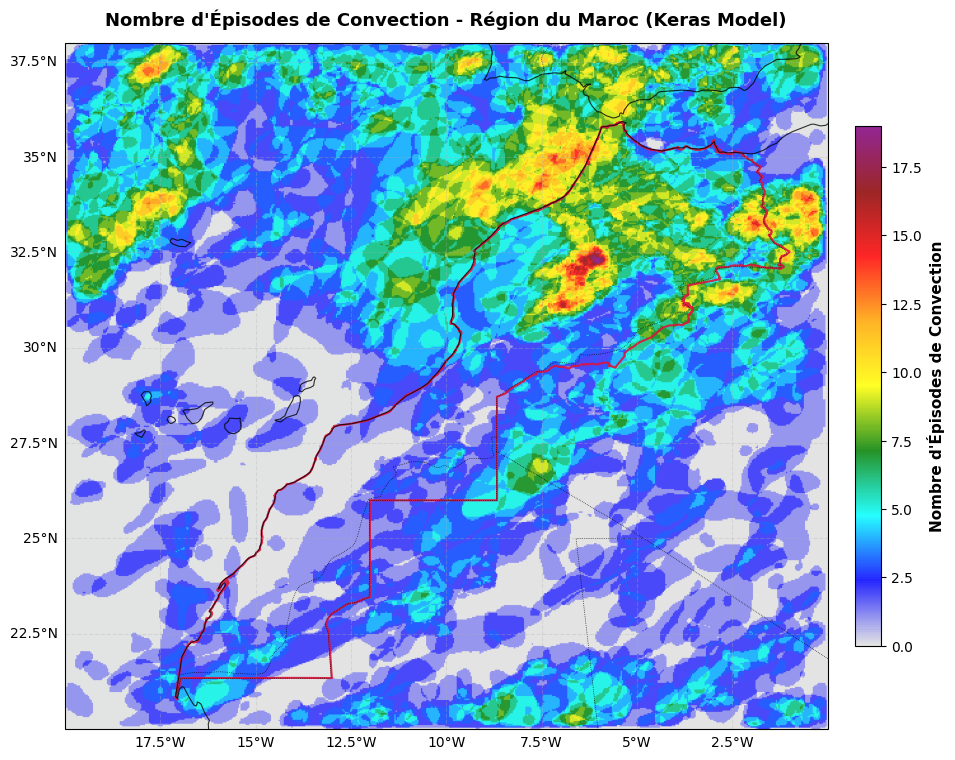

In [ ]:
import os
import glob
import argparse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd

# ==========================================
# 🛠️ QUICK CONFIGURATION (Change variables here)
# ==========================================
DEFAULT_IMAGE_FOLDER = "/content/drive/MyDrive/SI/data_2024/"
DEFAULT_MODEL_PATH = "content/drive/MyDrive/SI/callbacks/model_best.keras"
DEFAULT_OUTPUT_PATH = "/content/drive/MyDrive/SI/fig/nombre_episodes_convection_maroc.png"
DEFAULT_SHAPEFILE_PATH = "/content/drive/MyDrive/SI/shapefiles/Morocco_ADM0_simplified.simplified(1).geojson"

# Target size expected by your Keras model
MODEL_IMG_SIZE = (512, 512)

# Region of Interest [North, South, West, East]
ROI = [38, 20, -20, 0]
# ==========================================


def predict_segmentation_keras(image_path, model, img_size=(512, 512)):
    """Runs segmentation prediction on a single image file using the provided Keras model."""
    image = Image.open(image_path).convert("RGB")
    orig_w, orig_h = image.size

    # Preprocess image for model input
    image_resized = image.resize(img_size)
    image_array = np.array(image_resized, dtype=np.float32) / 255.0
    image_tensor = np.expand_dims(image_array, axis=0)

    # Run prediction
    pred = model.predict(image_tensor, verbose=0)
    mask = pred.squeeze()

    # Resize predicted binary mask back to original image dimensions
    mask_pil = Image.fromarray((mask > 0.5).astype(np.uint8))
    mask_resized = mask_pil.resize((orig_w, orig_h), resample=Image.NEAREST)
    binary_mask = np.array(mask_resized, dtype=np.uint16)

    return binary_mask


def generate_episode_count_from_model(image_folder, model, img_size=(512, 512)):
    """Iterates over all images in image_folder, predicts masks using Keras,

    and sums them into an episode count array.
    """
    extensions = ("*.tif", "*.png", "*.jpg", "*.jpeg")
    image_files = []
    for ext in extensions:
        image_files.extend(glob.glob(os.path.join(image_folder, ext)))

    if not image_files:
        print(f"❌ No input images found in: {image_folder}")
        return None

    print(f"📁 Found {len(image_files)} images to predict in {image_folder}")

    episode_count = None

    for i, img_path in enumerate(image_files):
        try:
            mask = predict_segmentation_keras(img_path, model, img_size=img_size)

            if episode_count is None:
                # Initialize accumulator based on the shape of the first image
                episode_count = np.zeros(mask.shape, dtype=np.uint32)

            # Check for shape consistency
            if mask.shape != episode_count.shape:
                print(f"⚠️ Warning: Image {os.path.basename(img_path)} size {mask.shape[::-1]} "
                      f"differs from initial shape {episode_count.shape[::-1]}. Resizing mask...")
                mask_pil = Image.fromarray(mask.astype(np.uint8))
                mask_pil = mask_pil.resize((episode_count.shape[1], episode_count.shape[0]), resample=Image.NEAREST)
                mask = np.array(mask_pil, dtype=np.uint32)

            episode_count += mask

            if (i + 1) % 10 == 0 or (i + 1) == len(image_files):
                print(f"  Processed [{i+1}/{len(image_files)}] images...")

        except Exception as e:
            print(f"⚠️ Failed prediction on {os.path.basename(img_path)}: {e}")

    return episode_count


def create_episode_colormap():
    colors = ['#E0E0E0', 'blue', 'cyan', 'green', 'yellow', 'orange', 'red', 'darkred', 'purple']
    return LinearSegmentedColormap.from_list('episode_count', colors, N=256)


def generate_map(episode_count, roi, shapefile_path=None, output_path=None):
    """Plots the accumulated episode map on Cartopy projection."""
    north, south, west, east = roi
    fig, ax = plt.subplots(figsize=(12, 9), subplot_kw={'projection': ccrs.PlateCarree()})

    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())

    # Features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, alpha=0.8)
    ax.add_feature(cfeature.OCEAN, facecolor='#EBF4FA', alpha=0.5)
    ax.add_feature(cfeature.LAND, facecolor='#F5F5F5', alpha=0.3)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)

    # Plot GeoJSON / Shapefile
    if shapefile_path and os.path.exists(shapefile_path):
        try:
            gdf = gpd.read_file(shapefile_path)
            if gdf.crs and gdf.crs != "EPSG:4326":
                gdf = gdf.to_crs(epsg=4326)
            gdf.plot(ax=ax, color='none', edgecolor='crimson', linewidth=1.5, alpha=0.9)
        except Exception as e:
            print(f"⚠️ Could not load shapefile: {e}")

    vmax = max(1, np.max(episode_count))
    cmap = create_episode_colormap()

    img_plot = ax.imshow(
        episode_count,
        cmap=cmap,
        vmin=0,
        vmax=vmax,
        extent=[west, east, south, north],
        origin='upper',
        transform=ccrs.PlateCarree(),
        alpha=0.85
    )

    # Colorbar
    cbar = plt.colorbar(img_plot, ax=ax, shrink=0.75, pad=0.03)
    cbar.set_label("Nombre d'Épisodes de Convection", fontsize=11, fontweight='bold')

    # Gridlines
    gl = ax.gridlines(draw_labels=True, alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False

    ax.set_title("Nombre d'Épisodes de Convection - Région du Maroc (Keras Model)",
                 fontsize=13, fontweight='bold', pad=12)

    # Save output
    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        plt.savefig(output_path, dpi=200, bbox_inches='tight', facecolor='white')
        print(f"✅ Map successfully generated & saved to: {output_path}")

    plt.show()
    plt.close()


def main(image_folder, model_input, output_path, shapefile_path=None):
    # 1. Load Keras Model
    if isinstance(model_input, str):
        print(f"🤖 Loading Keras model from: {model_input}")
        model = load_model(model_input)
    else:
        model = model_input

    # 2. Run segmentation predictions and aggregate count
    print("\n🚀 Running segmentation model over images...")
    episode_count = generate_episode_count_from_model(image_folder, model, img_size=MODEL_IMG_SIZE)

    if episode_count is None:
        return

    print(f"📊 Max convection episodes on a single pixel: {np.max(episode_count)}")

    # 3. Plot and save map
    print("🎨 Generating final map...")
    generate_map(episode_count, ROI, shapefile_path, output_path)


if __name__ == "__main__":
    main(
        image_folder=DEFAULT_IMAGE_FOLDER,
        model_input=modele,
        output_path=DEFAULT_OUTPUT_PATH,
        shapefile_path=DEFAULT_SHAPEFILE_PATH
    )

In [ ]:
target_img_paths[10]
import glob
glob.glob("/content/drive/MyDrive/SI/mask_opencv_2023/*2023-05-18T15-00-00.000Z.png")

['/content/drive/MyDrive/SI/mask_opencv_2023/mask_prod_2023-05-18T15-00-00.000Z.png']

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 790ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 816ms/step
Taille originale de l'image: (600, 521)
Taille du masque: (521, 600)


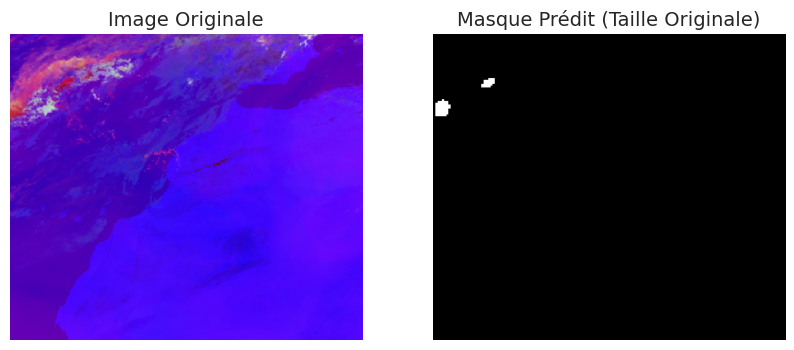

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt
import random

# ===== 1. Fonction de prédiction =====
def predire_segmentation_keras(chemin_image, modele, taille_image=(160, 160)):
    # Charger et prétraiter l'image
    predict_segmentation_keras(chemin_image,modele, img_size=(160, 160))
    image = Image.open(chemin_image).convert("RGB")
    taille_originale = image.size  # Stocker (largeur, hauteur) originale

    # Redimensionner pour l'entrée du modèle
    image_redimensionnee = image.resize(taille_image)
    tableau_image = np.array(image_redimensionnee) / 255.0  # normaliser [0,1]
    tenseur_image = np.expand_dims(tableau_image, axis=0)  # [1, H, W, 3]

    # Faire la prédiction
    prediction = modele.predict(tenseur_image)  # forme [1, H, W, 1] pour binaire
    masque = prediction.squeeze()  # [H, W]

    # Seuillage et redimensionnement aux dimensions originales
    masque_binaire = (masque > 0.5).astype(np.uint8)
    masque_redimensionne = Image.fromarray(masque_binaire).resize(
        taille_originale,
        resample=Image.NEAREST  # Préserver les contours nets
    )

    return image, np.array(masque_redimensionne)

# ===== 2. Visualisation =====
def afficher_segmentation(image, masque):
    plt.figure(figsize=(10, 5))

    # Image originale
    plt.subplot(1, 2, 1)
    plt.title("Image Originale")
    plt.imshow(image)
    plt.axis("off")

    # Superposition du masque
    plt.subplot(1, 2, 2)
    plt.title("Masque Prédit (Taille Originale)")
     #plt.imshow(image)
    plt.imshow(masque, cmap='gray')
    plt.axis("off")

    plt.show()

# ===== 3. Exécuter la prédiction =====
chemin_image = random.choice(test_input_img_paths)  # de votre séparation précédente
image, masque = predire_segmentation_keras(chemin_image, modele, taille_image=(160, 160))
print("Taille originale de l'image:", image.size)  # (largeur, hauteur)
print("Taille du masque:", masque.shape)  # Doit correspondre aux dimensions originales
afficher_segmentation(image, masque)

In [ ]:
chemin_image = random.choice(test_input_img_paths)  # de votre séparation précédente
image, masque = predire_segmentation_keras(chemin_image, modele, taille_image=(160, 160))
print(masque.sum())
print(masque)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 840ms/step
0
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


#4. Calcul des métriques IoT, Dice, cosine, Accuracy



##4.1 over test set

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU
import tensorflow as tf
import os

# ===== Métriques personnalisées =====
def dice_coef(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)  # Seuillage à 0.5
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred))

def cosine_similarity(y_true, y_pred):
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred > 0.5, [-1]).numpy().astype(np.float32)
    return np.dot(y_true, y_pred) / (np.linalg.norm(y_true) * np.linalg.norm(y_pred) + 1e-7)

# ===== Calcul des métriques pour un batch =====
def calculate_metrics(y_true, y_pred):
    y_true = y_true.numpy() if tf.is_tensor(y_true) else y_true
    y_pred = (y_pred > 0.5).astype(np.float32)

    # IoU
    iou_metric = MeanIoU(num_classes=2)
    iou_metric.update_state(y_true, y_pred)
    iou = iou_metric.result().numpy()

    # Dice
    dice = dice_coef(y_true, y_pred).numpy()

    # Cosine Similarity
    cosine = cosine_similarity(y_true, y_pred)

    # Accuracy
    accuracy = accuracy_score(y_true.flatten(), y_pred.flatten())

    return {
        'IoU': float(iou),
        'Dice': float(dice),
        'Cosine': float(cosine),
        'Accuracy': float(accuracy)
    }

# ===== Évaluation sur le jeu de test =====
def evaluate_and_save(model, test_images, test_masks, output_csv='metrics.csv'):
    results = []

    for img_path, mask_path in zip(test_images, test_masks):
        # Charger l'image et le masque
        image = np.array(Image.open(img_path).convert("RGB"))
        true_mask = np.array(Image.open(mask_path).convert("L")) / 255.0  # Normaliser [0,1]

        # Prédiction
        image,pred = predire_segmentation_keras(img_path, modele, taille_image=(160, 160))
        binary_pred = (pred > 0.5).astype(np.float32)
        # Calcul des métriques
        metrics = calculate_metrics(true_mask, binary_pred)
        metrics['Image'] = os.path.basename(img_path)
        results.append(metrics)

    # Sauvegarde en CSV
    df = pd.DataFrame(results)
    #df.to_csv(output_csv, index=False)
    print(f"Résultats sauvegardés dans {output_csv}")
    return df

# ===== Utilisation =====
df_metrics = evaluate_and_save(modele,
                               test_input_img_paths,
                               test_target_img_paths,
                               output_csv='resultats_metriques_test_2023.csv')

NameError: name 'test_input_img_paths' is not defined

In [ ]:
df_metrics = pd.read_csv('/content/drive/MyDrive/SI/metriques /only_2023/resultats_metriques_test_2023.csv')
df_metrics.describe()

,IoU,Dice,Cosine,Accuracy
count,255.000000,77.000000,255.000000,255.000000
mean,0.868692,0.209434,0.069515,0.993678
std,0.208737,0.286931,0.194611,0.016124
min,0.459440,0.000000,0.000000,0.896488
25%,0.702818,0.000000,0.000000,0.996977
50%,1.000000,0.000000,0.000000,1.000000
75%,1.000000,0.476357,0.000000,1.000000
max,1.000000,0.885594,0.890432,1.000000


##4.2 over all data 2023

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU
import tensorflow as tf
import os

# ===== Métriques personnalisées =====
def dice_coef(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)  # Seuillage à 0.5
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred))

def cosine_similarity(y_true, y_pred):
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred > 0.5, [-1]).numpy().astype(np.float32)
    return np.dot(y_true, y_pred) / (np.linalg.norm(y_true) * np.linalg.norm(y_pred) + 1e-7)

# ===== Calcul des métriques pour un batch =====
def calculate_metrics(y_true, y_pred):
    y_true = y_true.numpy() if tf.is_tensor(y_true) else y_true
    y_pred = (y_pred > 0.5).astype(np.float32)

    # IoU
    iou_metric = MeanIoU(num_classes=2)
    iou_metric.update_state(y_true, y_pred)
    iou = iou_metric.result().numpy()

    # Dice
    dice = dice_coef(y_true, y_pred).numpy()

    # Cosine Similarity
    cosine = cosine_similarity(y_true, y_pred)

    # Accuracy
    accuracy = accuracy_score(y_true.flatten(), y_pred.flatten())

    return {
        'IoU': float(iou),
        'Dice': float(dice),
        'Cosine': float(cosine),
        'Accuracy': float(accuracy)
    }

# ===== Évaluation sur le jeu de test =====
def evaluate_and_save(model, test_images, test_masks, output_csv='metrics.csv'):
    results = []

    for img_path, mask_path in zip(test_images, test_masks):
        # Charger l'image et le masque
        image = np.array(Image.open(img_path).convert("RGB"))
        true_mask = np.array(Image.open(mask_path).convert("L")) / 255.0  # Normaliser [0,1]

        # Prédiction
        image,pred = predire_segmentation_keras(img_path, modele, taille_image=(160, 160))
        binary_pred = (pred > 0.5).astype(np.float32)
        # Calcul des métriques
        metrics = calculate_metrics(true_mask, binary_pred)
        metrics['Image'] = os.path.basename(img_path)
        results.append(metrics)

    # Sauvegarde en CSV
    df = pd.DataFrame(results)
    df.to_csv(output_csv, index=False)
    print(f"Résultats sauvegardés dans {output_csv}")
    return df

# ===== Utilisation =====
df_metrics_all = evaluate_and_save(modele,
                               input_img_paths,
                               target_img_paths,
                               output_csv='resultats_metriques_2023.csv')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 787ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 767ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 756ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 773ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 771ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 774ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 769ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 785ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 740ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 795ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 790ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 771ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 770ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 768ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 764ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 794ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 775ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 746ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 783ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 757ms/step
1

In [ ]:
#df_metrics_all.to_csv('/content/drive/MyDrive/SI/metriques_2023.csv')
df_metrics_all = pd.read_csv('/content/drive/MyDrive/SI/metriques_2023.csv')

In [ ]:
df_metrics_all.describe()

,Unnamed: 0,IoU,Dice,Cosine,Accuracy
count,2552.000000,2552.000000,806.000000,2552.000000,2552.000000
mean,1275.500000,0.863414,0.220984,0.079148,0.992959
std,736.843267,0.210069,0.279470,0.201013,0.018224
min,0.000000,0.405993,0.000000,0.000000,0.801929
25%,637.750000,0.667835,0.000000,0.000000,0.996615
50%,1275.500000,1.000000,0.007235,0.000000,1.000000
75%,1913.250000,1.000000,0.469492,0.000000,1.000000
max,2551.000000,1.000000,0.922591,0.922616,1.000000


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image

# Configuration
DOSSIER_ENTREE = "dossier_images"
FICHIER_RESULTATS = "resultats_analyse_couleurs.csv"
os.makedirs("visualisations_couleurs", exist_ok=True)

# Plages de couleurs HSV (H:0-179, S:0-255, V:0-255)
PLAGES_COULEURS = {
    'rouge': [((0, 100, 100), (10, 255, 255)),
             ((170, 100, 100), (180, 255, 255))],
    'orange': [((10, 100, 100), (20, 255, 255))],
    'jaune': [((20, 100, 100), (30, 255, 255))]
}

def calculer_rapports_couleurs(chemin_image, modele):
    """Calcule les proportions de couleurs dans les zones segmentées"""
    # Obtenir la prédiction
    image_originale, masque_pred = predire_segmentation_keras(chemin_image, modele)
    hsv = cv2.cvtColor(np.array(image_originale), cv2.COLOR_RGB2HSV)

    resultats = {'fichier': os.path.basename(chemin_image)}
    pixels_masque = np.sum(masque_pred > 0)

    for nom_couleur, plages in PLAGES_COULEURS.items():
        masque_couleur = np.zeros_like(masque_pred)
        for (plage_basse, plage_haute) in plages:
            masque_couleur = cv2.bitwise_or(
                masque_couleur,
                cv2.inRange(hsv, np.array(plage_basse), np.array(plage_haute))
            )

        # Appliquer le masque de prédiction
        couleur_dans_masque = cv2.bitwise_and(masque_couleur, masque_pred)
        pixels_couleur = np.sum(couleur_dans_masque > 0)

        # Enregistrer les résultats
        resultats[f'pixels_{nom_couleur}'] = pixels_couleur
        resultats[f'ratio_{nom_couleur}'] = pixels_couleur/pixels_masque if pixels_masque>0 else 0
        """
        # Sauvegarder la visualisation (optionnel)
        if pixels_couleur > 0:
            region_coloree = cv2.bitwise_and(np.array(image_originale),
                                           np.array(image_originale),
                                           mask=couleur_dans_masque)
            cv2.imwrite(
                f"visualisations_couleurs/{nom_couleur}_{os.path.basename(chemin_image)}",
                cv2.cvtColor(region_coloree, cv2.COLOR_RGB2BGR)
            )
        """
    resultats['pixels_masque'] = pixels_masque
    return resultats

def analyser_couleurs(dossier_entree, modele):
    """Traiter toutes les images du dossier"""
    resultats = []
    extensions_valides = ('.png', '.jpg', '.jpeg', '.webp')
    fichiers_images = [f for f in os.listdir(dossier_entree)
                     if f.lower().endswith(extensions_valides)]

    for fichier in tqdm(fichiers_images, desc="Analyse des couleurs"):
        try:
            chemin_image = os.path.join(dossier_entree, fichier)
            resultats.append(calculer_rapports_couleurs(chemin_image, modele))
        except Exception as e:
            print(f"\nErreur avec {fichier}: {str(e)}")

    df = pd.DataFrame(resultats)

    # Déterminer la couleur dominante
    df['couleur_dominante'] = df[['ratio_rouge', 'ratio_orange', 'ratio_jaune']].idxmax(axis=1)
    df['couleur_dominante'] = df['couleur_dominante'].str.replace('ratio_', '')

    return df

In [ ]:
# Exécution principale
if __name__ == "__main__":
    # Analyser toutes les images
    df_2023 = analyser_couleurs("/content/drive/MyDrive/SI/data_2023", modele)

    # Sauvegarder les résultats
    df_2023.to_csv(FICHIER_RESULTATS, index=False)
    print(f"Résultats sauvegardés dans {FICHIER_RESULTATS}")

    # Générer un résumé
    resume = df_2023.describe(include='all')
    print("\nRésumé de l'analyse :")
    print(resume.loc[['mean', 'std', 'min', 'max'],
                  ['ratio_rouge', 'ratio_orange', 'ratio_jaune']])

    # Obtenir les images avec le plus de chaque couleur
    for couleur in ['rouge', 'orange', 'jaune']:
        top_images = df_2023.nlargest(3, f'ratio_{couleur}')[['fichier', f'ratio_{couleur}']]
        print(f"\nTop 3 images {couleur}:")
        print(top_images)

Analyse des couleurs:   0%|          | 0/2552 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 957ms/step


Analyse des couleurs:   0%|          | 1/2552 [00:01<53:15,  1.25s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 807ms/step


Analyse des couleurs:   0%|          | 2/2552 [00:02<44:22,  1.04s/it]

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 779ms/step


Analyse des couleurs: 100%|█████████▉| 2551/2552 [1:00:08<00:01,  1.49s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 769ms/step


Analyse des couleurs: 100%|██████████| 2552/2552 [1:00:10<00:00,  1.41s/it]

Résultats sauvegardés dans resultats_analyse_couleurs.csv

Résumé de l'analyse :
      ratio_rouge  ratio_orange  ratio_jaune
mean     0.070223      0.001593     0.000434
std      0.164019      0.011973     0.007004
min      0.000000      0.000000     0.000000
max      1.000000      0.217641     0.293384

Top 3 images rouge:
                                fichier  ratio_rouge
243   prod_2023-08-30T12-00-00.000Z.png     1.000000
132   prod_2023-08-21T09-00-00.000Z.png     0.858131
1591  prod_2023-06-06T12-00-00.000Z.png     0.839461

Top 3 images orange:
                                fichier  ratio_orange
1948  prod_2023-08-16T18-00-00.000Z.png      0.217641
35    prod_2023-08-18T15-00-00.000Z.png      0.212965
249   prod_2023-09-05T18-00-00.000Z.png      0.184692

Top 3 images jaune:
                                fichier  ratio_jaune
1948  prod_2023-08-16T18-00-00.000Z.png     0.293384
35    prod_2023-08-18T15-00-00.000Z.png     0.117767
87    prod_2023-09-16T15-00-00.000Z.png    

In [ ]:
#df_2023.to_csv('/content/drive/MyDrive/SI/colore_ratio_2023.csv')

In [ ]:
df_2023 = pd.read_csv('/content/drive/MyDrive/SI/colore_ratio_2023.csv')
df_2023.describe()

,Unnamed: 0,pixels_rouge,ratio_rouge,pixels_orange,ratio_orange,pixels_jaune,ratio_jaune,pixels_masque
count,2552.000000,2552.000000,2552.000000,2552.000000,2552.000000,2552.000000,2552.000000,2552.000000
mean,1275.500000,530.192398,0.070223,7.027038,0.001593,1.644201,0.000434,1266.811912
std,736.843267,1884.030567,0.164019,57.893030,0.011973,29.347263,0.007004,3833.049750
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,637.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1275.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1913.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2551.000000,28416.000000,1.000000,1774.000000,0.217641,981.000000,0.293384,39661.000000


#6 analyser images par couleur

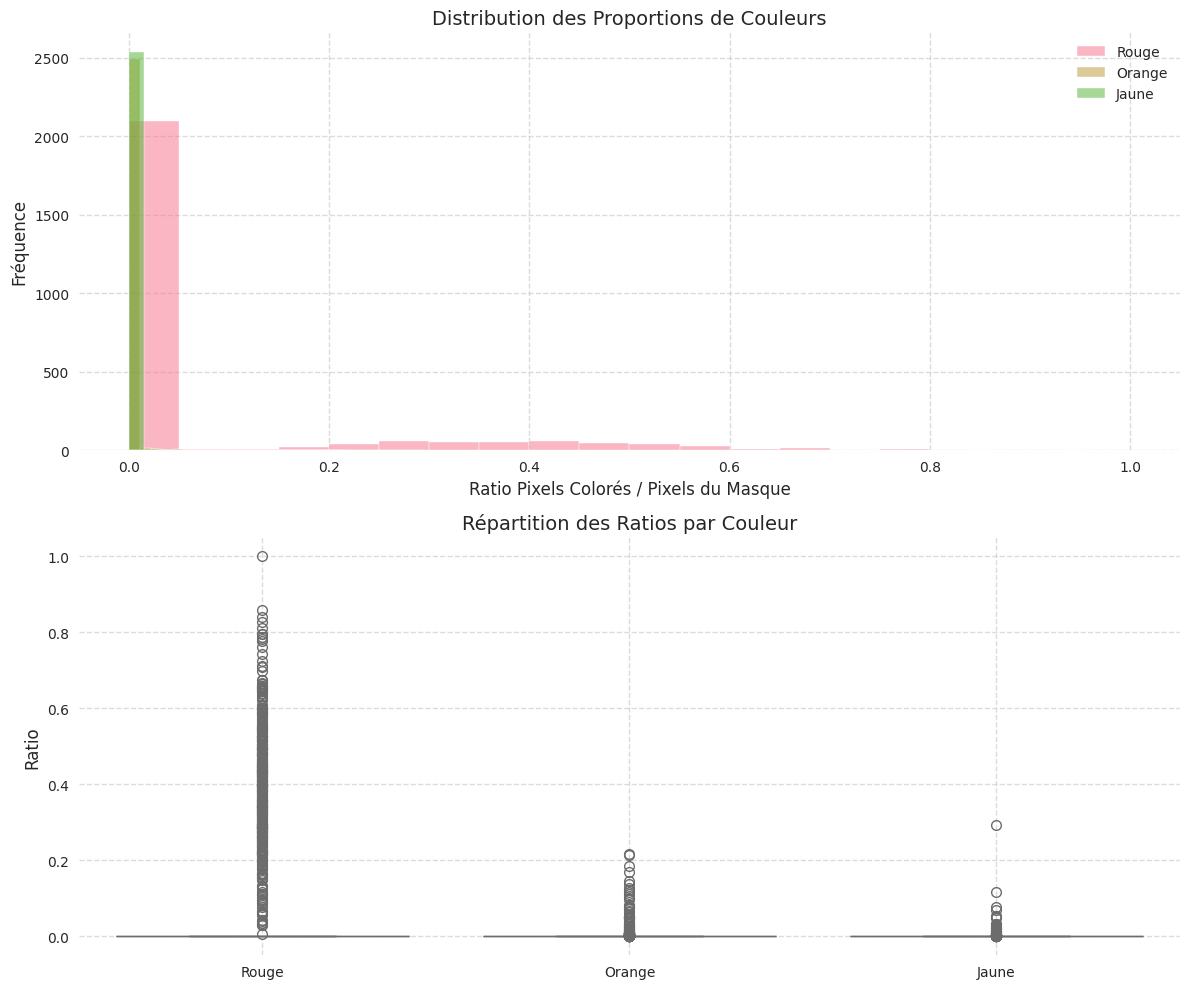

/tmp/ipython-input-1692395036.py:53: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.histplot(data=df_dominant, x='couleur_dominante', hue='couleur_dominante',


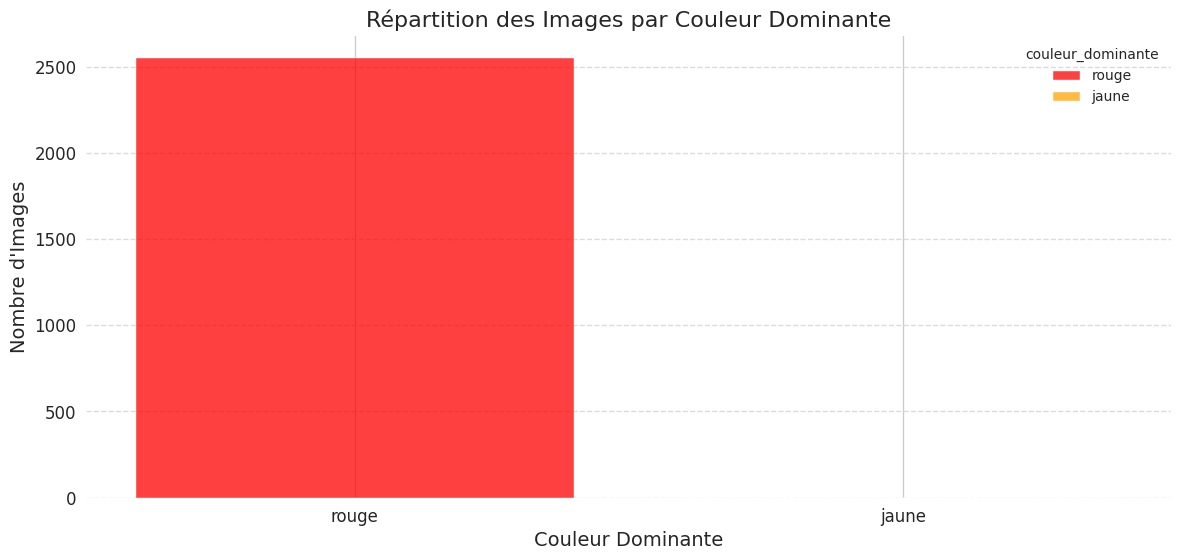


Statistiques des Ratios :
      ratio_rouge  ratio_orange  ratio_jaune
mean     0.070223      0.001593     0.000434
50%      0.000000      0.000000     0.000000
std      0.164019      0.011973     0.007004


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
# Configuration des styles
plt.style.use('seaborn-v0_8')  # Style valide pour les nouvelles versions
rcParams['font.family'] = 'DejaVu Sans'  # Police compatible avec accents
sns.set_palette("husl")
sns.set_style("whitegrid")

def visualiser_distributions(df):
    """Visualise les distributions des ratios de couleur"""
    # Création d'une figure avec 2 sous-graphiques
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

    # Histogrammes superposés
    for couleur in ['rouge', 'orange', 'jaune']:
        sns.histplot(data=df, x=f'ratio_{couleur}', bins=20,
                    alpha=0.5, label=couleur.capitalize(), ax=ax1)

    ax1.set_title('Distribution des Proportions de Couleurs', fontsize=14)
    ax1.set_xlabel('Ratio Pixels Colorés / Pixels du Masque', fontsize=12)
    ax1.set_ylabel('Fréquence', fontsize=12)
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Boîtes à moustaches
    donnees_melt = df.melt(value_vars=['ratio_rouge', 'ratio_orange', 'ratio_jaune'],
                          var_name='Couleur', value_name='Ratio')
    donnees_melt['Couleur'] = donnees_melt['Couleur'].str.replace('ratio_', '').str.capitalize()

    sns.boxplot(data=donnees_melt, x='Couleur', y='Ratio', ax=ax2)
    ax2.set_title('Répartition des Ratios par Couleur', fontsize=14)
    ax2.set_xlabel('')
    ax2.set_ylabel('Ratio', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)

    # Ajustement de l'espacement
    plt.tight_layout()

    # Sauvegarde des graphiques
    plt.savefig('distributions_couleurs.png', dpi=300, bbox_inches='tight')
    plt.show()

def analyser_images_par_couleur(df):
    """Analyse approfondie par couleur dominante"""
    # Préparation des données
    df_dominant = df[df['couleur_dominante'] != ''].copy()

    # Configuration du graphique
    plt.figure(figsize=(14, 6))

    # Histogramme empilé
    sns.histplot(data=df_dominant, x='couleur_dominante', hue='couleur_dominante',
                multiple="stack", shrink=0.8, palette=['#FF0000', '#FFA500', '#FFFF00'])

    # Personnalisation
    plt.title('Répartition des Images par Couleur Dominante', fontsize=16)
    plt.xlabel('Couleur Dominante', fontsize=14)
    plt.ylabel('Nombre d\'Images', fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Sauvegarde
    plt.savefig('repartition_dominante.png', dpi=300, bbox_inches='tight')
    plt.show()

# Après avoir chargé vos données (df = pd.read_csv('resultats_analyse_couleurs.csv'))
if __name__ == "__main__":
    # Visualisation des distributions
    visualiser_distributions(df_2023)

    # Analyse par couleur dominante
    analyser_images_par_couleur(df_2023)

    # Affichage des statistiques clés
    print("\nStatistiques des Ratios :")
    print(df_2023[['ratio_rouge', 'ratio_orange', 'ratio_jaune']].describe().loc[['mean', '50%', 'std']])

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image

# Configuration
FICHIER_RESULTATS = "/content/drive/MyDrive/SI/visualisations_couleurs/resultats_analyse_couleurs_2023.csv"
os.makedirs("/content/drive/MyDrive/SI/visualisations_couleurs", exist_ok=True)

# Plages de couleurs HSV (H:0-179, S:0-255, V:0-255)
PLAGES_COULEURS = {
    'rouge': [((0, 100, 100), (10, 255, 255)),
             ((170, 100, 100), (180, 255, 255))],
    'orange': [((10, 100, 100), (20, 255, 255))],
    'jaune': [((20, 100, 100), (30, 255, 255))]
}

def calculer_rapports_couleurs(chemin_image, modele):
    """Calcule les proportions de couleurs dans les zones segmentées"""
    # Obtenir la prédiction
    image_originale, masque_pred = predire_segmentation_keras(chemin_image, modele)
    hsv = cv2.cvtColor(np.array(image_originale), cv2.COLOR_RGB2HSV)

    resultats = {'fichier': os.path.basename(chemin_image)}
    pixels_masque = np.sum(masque_pred > 0)

    for nom_couleur, plages in PLAGES_COULEURS.items():
        masque_couleur = np.zeros_like(masque_pred)
        for (plage_basse, plage_haute) in plages:
            masque_couleur = cv2.bitwise_or(
                masque_couleur,
                cv2.inRange(hsv, np.array(plage_basse), np.array(plage_haute))
            )

        # Appliquer le masque de prédiction
        couleur_dans_masque = cv2.bitwise_and(masque_couleur, masque_pred)
        pixels_couleur = np.sum(couleur_dans_masque > 0)
        total_pixels_couleur = np.sum(masque_couleur > 0)

        # Enregistrer les résultats
        resultats[f'pixels_{nom_couleur}'] = pixels_couleur
        resultats[f'total_pixels_{nom_couleur}'] = total_pixels_couleur
        resultats[f'coverage_{nom_couleur}'] = pixels_couleur / total_pixels_couleur if total_pixels_couleur > 0 else 0
        resultats[f'density_{nom_couleur}'] = pixels_couleur / pixels_masque if pixels_masque > 0 else 0

        # Sauvegarder la visualisation
        if pixels_couleur > 0:
            region_coloree = cv2.bitwise_and(
                np.array(image_originale),
                np.array(image_originale),
                mask=couleur_dans_masque
            )
            cv2.imwrite(
                f"visualisations_couleurs/{nom_couleur}_{os.path.basename(chemin_image)}",
                cv2.cvtColor(region_coloree, cv2.COLOR_RGB2BGR)
            )

    resultats['pixels_masque'] = pixels_masque
    return resultats

def analyser_couleurs(dossier_entree, modele):
    """Traiter toutes les images du dossier"""
    resultats = []
    extensions_valides = ('.png', '.jpg', '.jpeg', '.webp')
    fichiers_images = [f for f in os.listdir(dossier_entree)
                     if f.lower().endswith(extensions_valides)]

    for fichier in tqdm(fichiers_images, desc="Analyse des couleurs"):
        try:
            chemin_image = os.path.join(dossier_entree, fichier)
            resultats.append(calculer_rapports_couleurs(chemin_image, modele))
        except Exception as e:
            print(f"\nErreur avec {fichier}: {str(e)}")

    df = pd.DataFrame(resultats)

    # Calculer les ratios globaux (agrégation sur toutes les images)
    global_results = {'pixels_masque_total': df['pixels_masque'].sum()}

    for nom_couleur in PLAGES_COULEURS:
        total_pixels_couleur = df[f'total_pixels_{nom_couleur}'].sum()
        pixels_couleur_dans_masque = df[f'pixels_{nom_couleur}'].sum()

        global_results[f'global_coverage_{nom_couleur}'] = (
            pixels_couleur_dans_masque / total_pixels_couleur
            if total_pixels_couleur > 0
            else 0
        )

        global_results[f'global_density_{nom_couleur}'] = (
            pixels_couleur_dans_masque / global_results['pixels_masque_total']
            if global_results['pixels_masque_total'] > 0
            else 0
        )

    # Sauvegarder les résultats globaux
    pd.DataFrame([global_results]).to_csv("resultats_globaux.csv", index=False)

    # Déterminer la couleur dominante par image (basé sur la densité dans le masque)
    densite_cols = [f'density_{c}' for c in PLAGES_COULEURS]
    df['couleur_dominante'] = df[densite_cols].idxmax(axis=1)
    df['couleur_dominante'] = df['couleur_dominante'].str.replace('density_', '')

    return df, global_results

In [ ]:
# Exécution principale
if __name__ == "__main__":
    # Analyser toutes les images
    df, global_results = analyser_couleurs("/content/drive/MyDrive/SI/data_2023", modele)

Analyse des couleurs:   0%|          | 0/2552 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


Analyse des couleurs:   0%|          | 1/2552 [00:06<4:45:47,  6.72s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 840ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 839ms/step


Analyse des couleurs:   0%|          | 2/2552 [00:09<3:04:53,  4.35s/it]

...

Analyse des couleurs: 100%|█████████▉| 2550/2552 [2:20:50<00:06,  3.39s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 869ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 859ms/step


Analyse des couleurs: 100%|█████████▉| 2551/2552 [2:20:53<00:03,  3.32s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 865ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 847ms/step


Analyse des couleurs: 100%|██████████| 2552/2552 [2:20:57<00:00,  3.31s/it]


In [ ]:
#df.to_csv(FICHIER_RESULTATS,index=False)

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/SI/visualisations_couleurs/resultats_analyse_couleurs_2023.csv')

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/SI/visualisations_couleurs/2023/resultats_globaux.csv")
global_results = df.iloc[0].to_dict()
global_results

{'pixels_masque_total': 3232904.0,
 'global_coverage_rouge': 0.6885559495505471,
 'global_density_rouge': 0.4185249546537726,
 'global_coverage_orange': 0.8693101943865432,
 'global_density_orange': 0.0055470252132448,
 'global_coverage_jaune': 0.8846721484292642,
 'global_density_jaune': 0.001297904299045}

In [ ]:
COLOR_MAP = {
        'rouge': 'red',
        'orange': 'orange',
        'jaune': 'yellow'
    }

def generer_plots_finaux(df_per_image, global_results):
    """Génère uniquement les deux derniers plots demandés"""
    # 1. Création de la figure principale (1x2)
    plt.figure(figsize=(18, 7))

    # 1.1 Violin Plot pour la couverture des couleurs
    plt.subplot(1, 2, 1)
    coverage_cols = [f'coverage_{c}' for c in PLAGES_COULEURS]
    coverage_data = df_per_image[coverage_cols]
    coverage_data.columns = [col.replace('coverage_', '') for col in coverage_cols]

    # Créer un violin plot amélioré
    ax = sns.violinplot(
        data=coverage_data,
        palette=['red', 'orange', 'yellow'],
        inner="quartile",  # Afficher les quartiles
        cut=0,            # Couper au niveau des données min/max
        bw_method=0.5     # Paramètre de lissage
    )

    # Ajouter les moyennes
    for i, color in enumerate(PLAGES_COULEURS):
        mean_val = coverage_data[color].mean()
        plt.scatter(i, mean_val, color='white', s=100, zorder=5)
        plt.scatter(i, mean_val, color='black', s=40, marker='D', zorder=6)
        plt.text(i, mean_val + 0.05, f'Moy: {mean_val:.2f}',
                 ha='center', fontsize=10, fontweight='bold')

    plt.title('Distribution de la Couverture des Couleurs', fontsize=14)
    plt.ylabel('Proportion de couleur présente dans le masque', fontsize=12)
    plt.xlabel('Couleur', fontsize=12)
    plt.grid(True, axis='y', linestyle='--', alpha=0.3)

    # 1.2 Bar Plot pour les résultats globaux
    plt.subplot(1, 2, 2)
    global_metrics = {}
    colors = list(PLAGES_COULEURS.keys())

    # Extraire les résultats globaux
    for color in colors:
        global_metrics[f'Couverture {color}'] = global_results[f'global_coverage_{color}']
        global_metrics[f'Densité {color}'] = global_results[f'global_density_{color}']

    # Créer un bar plot
    metrics_df = pd.DataFrame(list(global_metrics.items()),
                             columns=['Métrique', 'Valeur'])
    bar_plot = sns.barplot(
        x='Métrique',
        y='Valeur',
        data=metrics_df,
        palette=['red', 'orange', 'yellow'] * 2
    )

    # Améliorer la lisibilité
    plt.title('Métriques Globales de Couleur', fontsize=14)
    plt.ylabel('Valeur', fontsize=12)
    plt.xlabel('')
    plt.xticks(rotation=15, ha='right', fontsize=10)

    # Définir les limites de l'axe Y
    y_max = 1.1 * metrics_df['Valeur'].max()
    plt.ylim(0, y_max if y_max > 0 else 1)

    # Ajouter les valeurs sur les barres
    for i, bar in enumerate(bar_plot.patches):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.,
                 height + 0.01,
                 f'{height:.3f}',
                 ha='center', va='bottom',
                 fontsize=10)

    # Ajouter une légende pour distinguer couverture et densité
    plt.text(0.02, 0.95, 'Couverture: Proportion dans le masque / Total couleur',
             transform=plt.gca().transAxes, fontsize=9,
             bbox=dict(facecolor='white', alpha=0.8))
    plt.text(0.02, 0.88, 'Densité: Proportion dans le masque / Taille masque',
             transform=plt.gca().transAxes, fontsize=9,
             bbox=dict(facecolor='white', alpha=0.8))

    # Ajustement et sauvegarde
    plt.tight_layout()
    plt.savefig('violin_et_global.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 2. Scatter Plots: Relation densité vs couverture
    plt.figure(figsize=(16, 6))
    for i, color in enumerate(PLAGES_COULEURS.keys(), 1):
        plt.subplot(1, 3, i)

        # Créer le scatter plot avec régression
        ax = sns.regplot(
            data=df_per_image,
            x=f'density_{color}',
            y=f'coverage_{color}',
            color=COLOR_MAP[color],
            scatter_kws={'alpha': 0.6, 's': 60},
            line_kws={'color': 'black', 'linestyle': '--', 'alpha': 0.7}
        )

        # Ajouter la corrélation
        corr = df_per_image[[f'density_{color}', f'coverage_{color}']].corr().iloc[0,1]
        plt.annotate(f'Corrélation: {corr:.2f}',
                    xy=(0.05, 0.95),
                    xycoords='axes fraction',
                    fontsize=11,
                    bbox=dict(boxstyle="round", facecolor='white', alpha=0.8))

        # Configuration
        plt.title(f'Relation Densité vs Couverture: {color}', fontsize=13)
        plt.xlabel('Densité (proportion dans le masque)', fontsize=11)
        plt.ylabel('Couverture (proportion dans l\'image)', fontsize=11)
        plt.grid(True, linestyle='--', alpha=0.3)
        plt.xlim(-0.05, 1.05)
        plt.ylim(-0.05, 1.05)

    plt.tight_layout()
    plt.savefig('densite_vs_couverture.png', dpi=300)
    plt.show()

In [ ]:
def generer_violin_plot_filtre(df_per_image):
    """Génère un violin plot uniquement pour les valeurs de couverture > 0"""
    plt.figure(figsize=(10, 6))

    # Préparer les données filtrées
    coverage_data = []
    for couleur in PLAGES_COULEURS:
        col_name = f'coverage_{couleur}'
        # Filtrer pour ne garder que les valeurs > 0
        valeurs_filtrees = df_per_image[df_per_image[col_name] > 0][col_name]
        for valeur in valeurs_filtrees:
            coverage_data.append({
                'Couleur': couleur,
                'Couverture': valeur
            })

    coverage_df = pd.DataFrame(coverage_data)

    # Créer le violin plot avec les données filtrées
    ax = sns.violinplot(
        x='Couleur',
        y='Couverture',
        data=coverage_df,
        palette={'rouge': 'red', 'orange': 'orange', 'jaune': 'yellow'},
        inner="quartile",
        cut=0,
        bw_method=0.3
    )

    # Ajouter les statistiques descriptives
    for i, couleur in enumerate(PLAGES_COULEURS):
        # Calculer les stats sur les données filtrées
        donnees_couleur = coverage_df[coverage_df['Couleur'] == couleur]['Couverture']
        moyenne = donnees_couleur.mean()
        mediane = donnees_couleur.median()

        # Afficher les marqueurs
        plt.scatter(i, moyenne, color='white', s=100, zorder=5)
        plt.scatter(i, moyenne, color='black', s=40, marker='D', zorder=6)

        # Annotations
        plt.text(i, moyenne + 0.03, f'Moy: {moyenne:.2f}\nMéd: {mediane:.2f}',
                ha='center', fontsize=9, bbox=dict(facecolor='white', alpha=0.8))

    # Configuration du graphique
    plt.title('Distribution de la Couverture des Couleurs (valeurs > 0)', fontsize=14)
    plt.xlabel('Couleur', fontsize=12)
    plt.ylabel('Proportion de couleur dans le masque', fontsize=12)
    plt.ylim(-0.05, 1.05)
    plt.grid(True, axis='y', linestyle='--', alpha=0.3)

    # Ajouter des informations sur le filtrage
    total_images = len(df_per_image)
    for i, couleur in enumerate(PLAGES_COULEURS):
        count = len(coverage_df[coverage_df['Couleur'] == couleur])
        plt.text(i, -0.1, f"{count}/{total_images}",
                ha='center', fontsize=9, color='blue')

    plt.tight_layout()
    plt.savefig('violin_plot_filtre.png', dpi=300)
    plt.show()

/tmp/ipython-input-1769068911.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(


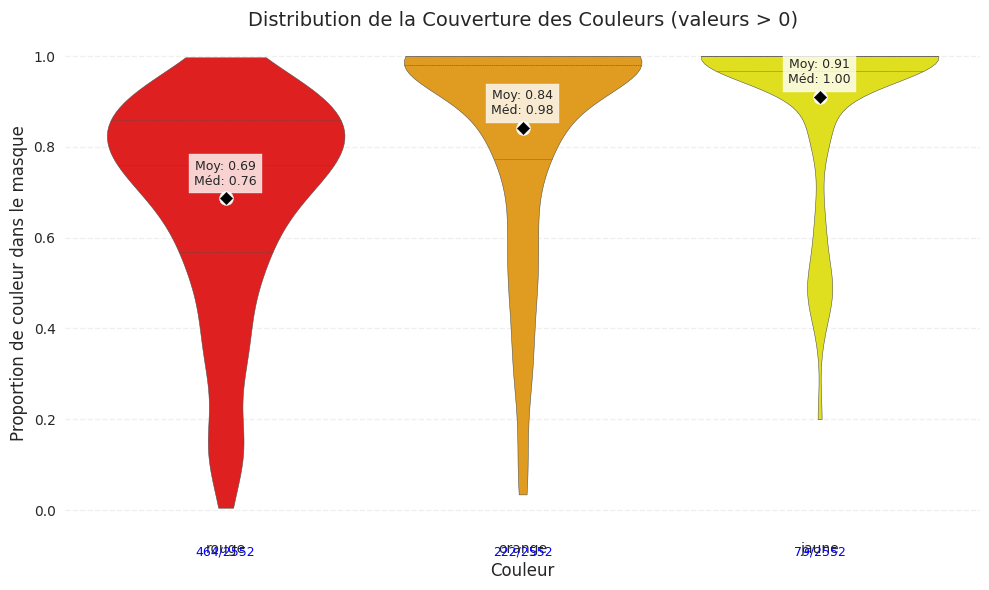

In [ ]:
generer_violin_plot_filtre(df)

/tmp/ipython-input-2224224762.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar_plot = sns.barplot(


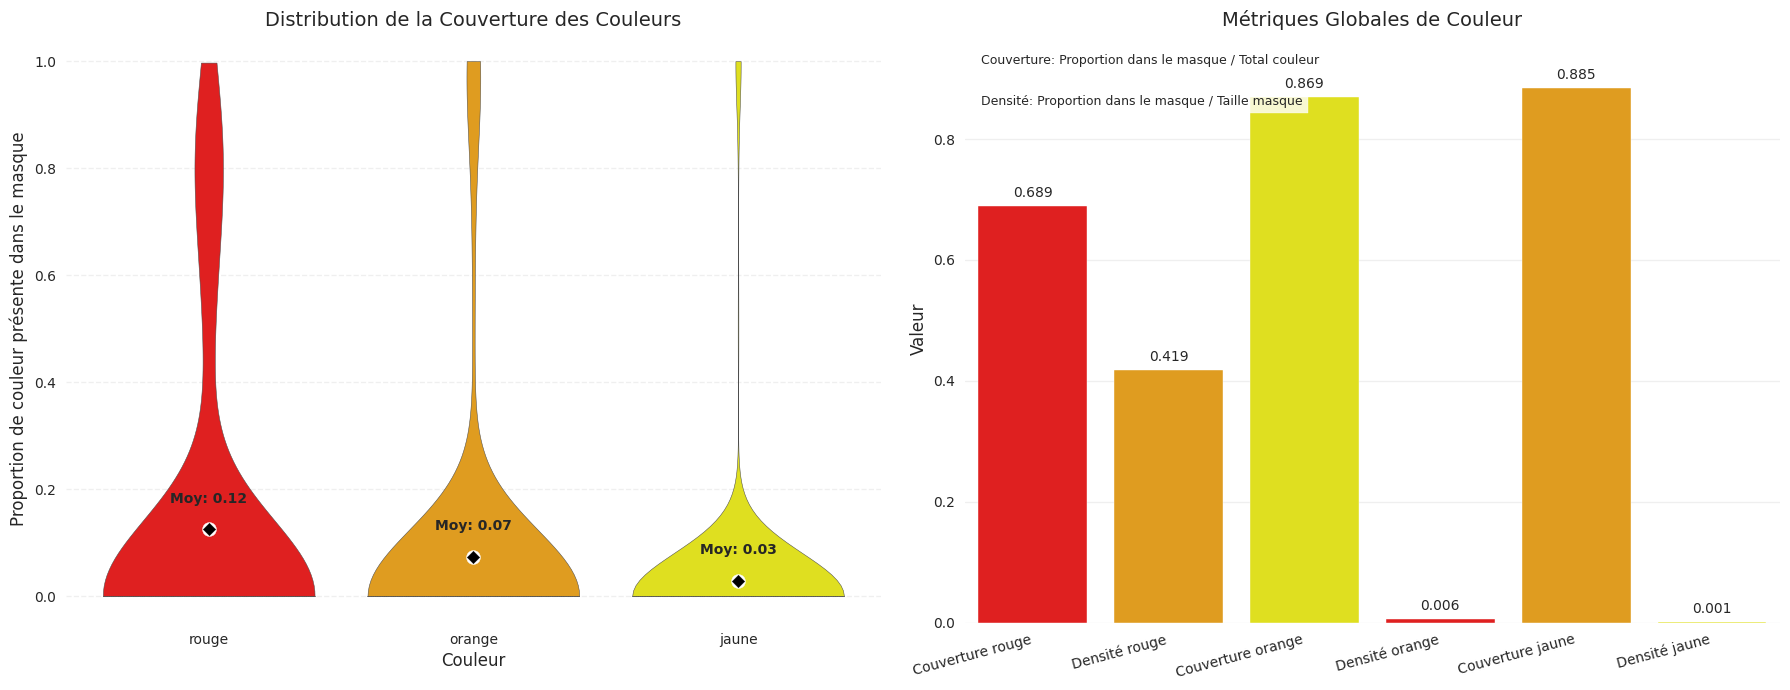

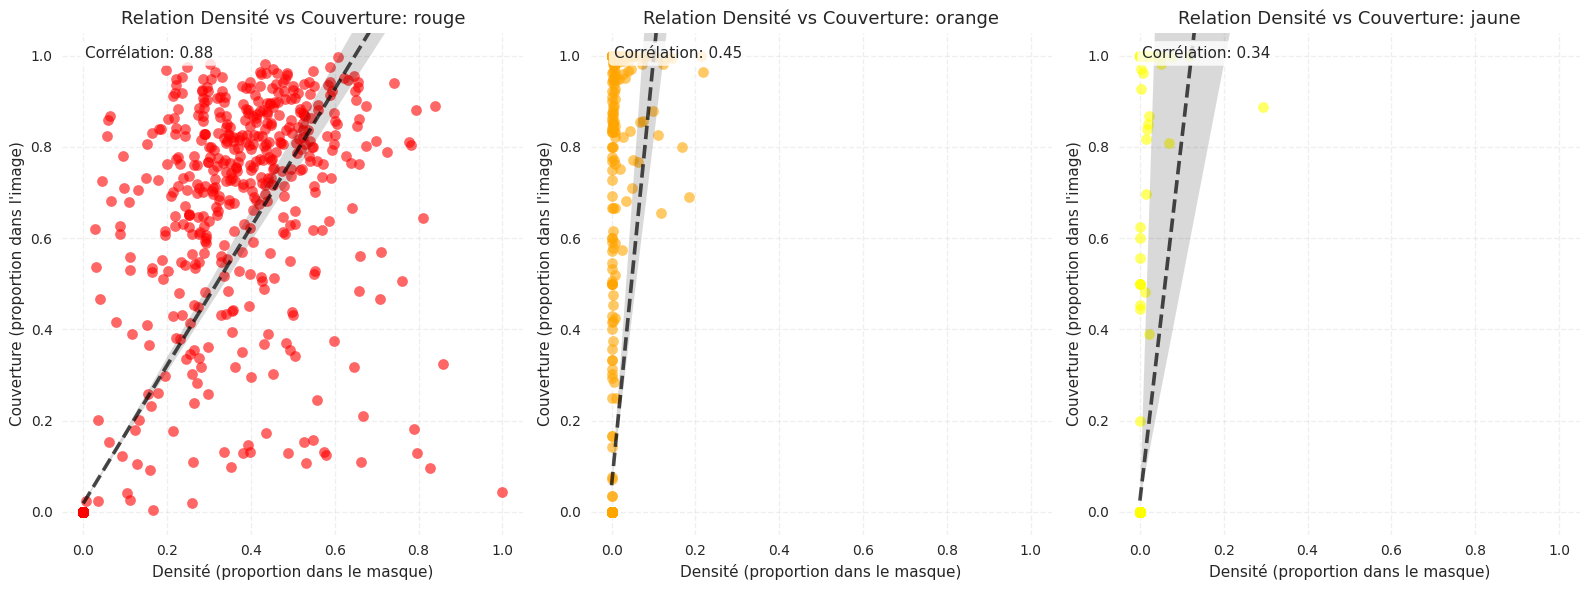

In [ ]:
generer_plots_finaux(df, global_results)

In [ ]:
PLAGES_COULEURS

{'rouge': [((0, 100, 100), (10, 255, 255)),
  ((170, 100, 100), (180, 255, 255))],
 'orange': [((10, 100, 100), (20, 255, 255))],
 'jaune': [((20, 100, 100), (30, 255, 255))]}

In [ ]:
def visualiser_histogrammes_couverture(df_per_image):
    """Visualise la distribution de couverture avec des histogrammes et des couleurs valides"""
    # Mappage des noms de couleur français vers des valeurs de couleur reconnues
    COLOR_MAP = {
        'rouge': 'red',
        'orange': 'orange',
        'jaune': 'yellow'
    }

    plt.figure(figsize=(12, 8))

    for i, couleur in enumerate(PLAGES_COULEURS, 1):
        plt.subplot(2, 2, i)

        # Filtrer les valeurs non nulles
        valeurs = df_per_image[f'coverage_{couleur}']
        valeurs = valeurs[valeurs > 0]

        # Créer l'histogramme avec la couleur mappée
        sns.histplot(valeurs, bins=20, color=COLOR_MAP[couleur], kde=True)

        # Ajouter une ligne pour la moyenne
        moyenne = valeurs.mean()
        plt.axvline(moyenne, color='black', linestyle='--')
        plt.text(moyenne + 0.02, plt.ylim()[1]*0.9, f'Moy: {moyenne:.2f}', fontsize=10)

        plt.title(f'Couverture du {couleur.capitalize()}')
        plt.xlabel('Proportion dans le masque')
        plt.ylabel('Nombre d\'images')
        plt.xlim(-0.05, 1.05)
        plt.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.savefig('histogrammes_couverture_couleurs.png', dpi=300)
    plt.show()

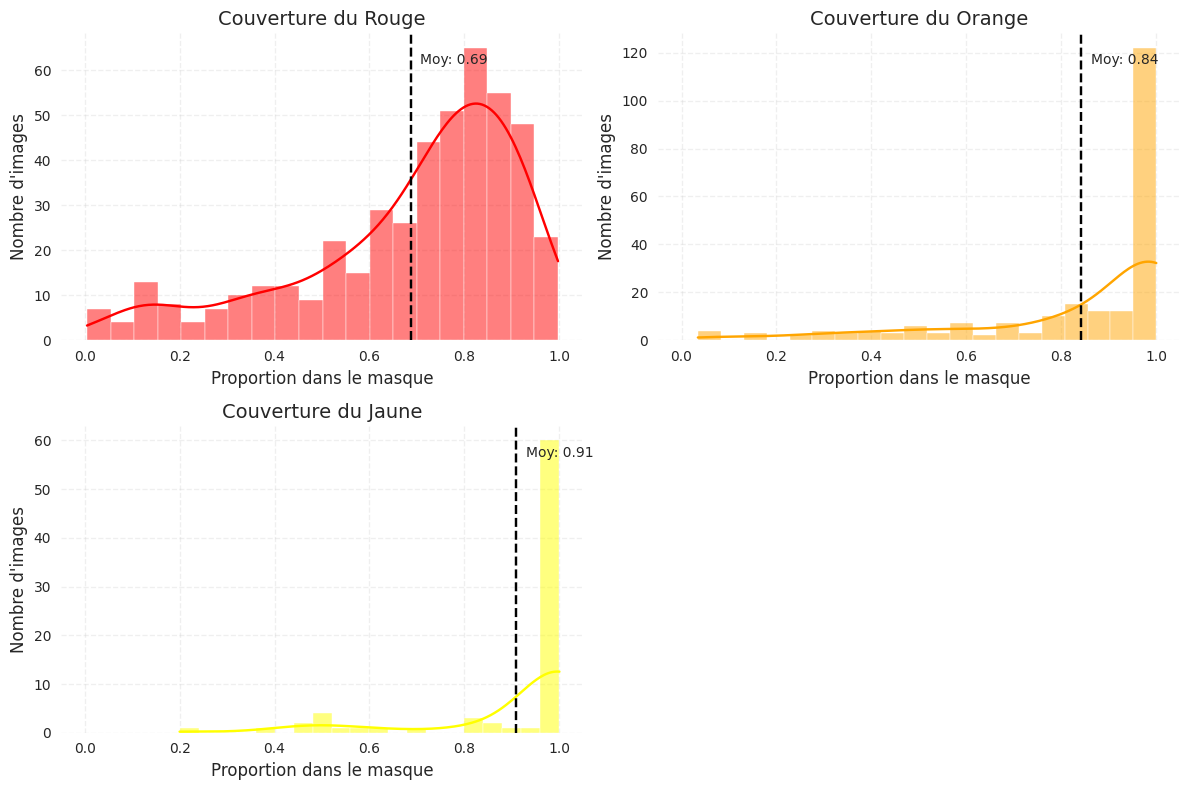

In [ ]:
visualiser_histogrammes_couverture(df)